<b>ML Experiment 9: Implementation of K-Means Clustering</b><br><br><b>Aim:</b> Cluster customer order frequency and average order value using K-Means, selecting optimal K via Elbow WCSS and Silhouette Score.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
rng = np.random.default_rng(913)
segment_centers = [(4, 180), (6, 720), (14, 460), (24, 195), (26, 780)]
batches = []
for orders_mu, aov_mu in segment_centers:
    batches.append(np.column_stack([
        rng.normal(orders_mu, 1.8, 44),
        rng.normal(aov_mu, 55.0, 44),
    ]))
rfm_matrix = np.vstack(batches)

rfm_df = pd.DataFrame({
    "Monthly_Orders": np.round(np.clip(rfm_matrix[:, 0], 1, 35), 1),
    "Avg_Order_Value": np.round(np.clip(rfm_matrix[:, 1], 80, 980), 1),
})

scaler = StandardScaler()
x_scaled = scaler.fit_transform(rfm_df)

k_candidates = list(range(2, 10))
wcss_vals = [KMeans(n_clusters=1, n_init=10, random_state=913).fit(x_scaled).inertia_]
sil_vals = []

for k in k_candidates:
    km_model = KMeans(n_clusters=k, n_init=10, random_state=913)
    assigns = km_model.fit_predict(x_scaled)
    wcss_vals.append(km_model.inertia_)
    sil_vals.append(silhouette_score(x_scaled, assigns))

best_k = k_candidates[int(np.argmax(sil_vals))]

In [3]:
final_km = KMeans(n_clusters=best_k, n_init=10, random_state=913)
rfm_df["Cluster"] = final_km.fit_predict(x_scaled)
centers_orig = scaler.inverse_transform(final_km.cluster_centers_)

print("K-Means Elbow & Silhouette Metrics:")
print(pd.DataFrame({
    "K": k_candidates,
    "WCSS": np.round(wcss_vals[1:], 2),
    "Silhouette": np.round(sil_vals, 4),
}).to_string(index=False))

print(f"\nSelected Optimal K: {best_k}")
print("Cluster Profiles:")
print(rfm_df.groupby("Cluster").agg(
    Customers=("Monthly_Orders", "count"),
    Mean_Orders=("Monthly_Orders", "mean"),
    Mean_Order_Value=("Avg_Order_Value", "mean"),
).round(2))

wine = load_wine()
wine_scaled = StandardScaler().fit_transform(wine.data)
wine_clusters = KMeans(n_clusters=3, n_init=10, random_state=913).fit_predict(wine_scaled)
print(f"\nWine K=3 Silhouette: {silhouette_score(wine_scaled, wine_clusters):.4f}")
print(f"Wine Adjusted Rand Index: {adjusted_rand_score(wine.target, wine_clusters):.4f}")

K-Means Elbow & Silhouette Metrics:
 K   WCSS  Silhouette
 2 257.12      0.4285
 3 139.46      0.5535
 4  53.62      0.6900
 5  15.79      0.7671
 6  14.28      0.6814
 7  12.93      0.5911
 8  11.83      0.5105
 9  10.63      0.4252

Selected Optimal K: 5
Cluster Profiles:
         Customers  Mean_Orders  Mean_Order_Value
Cluster                                          
0               44        26.32            796.12
1               44        13.99            460.11
2               44         3.72            175.13
3               44        23.86            188.71
4               44         5.93            719.72

Wine K=3 Silhouette: 0.2849
Wine Adjusted Rand Index: 0.8975


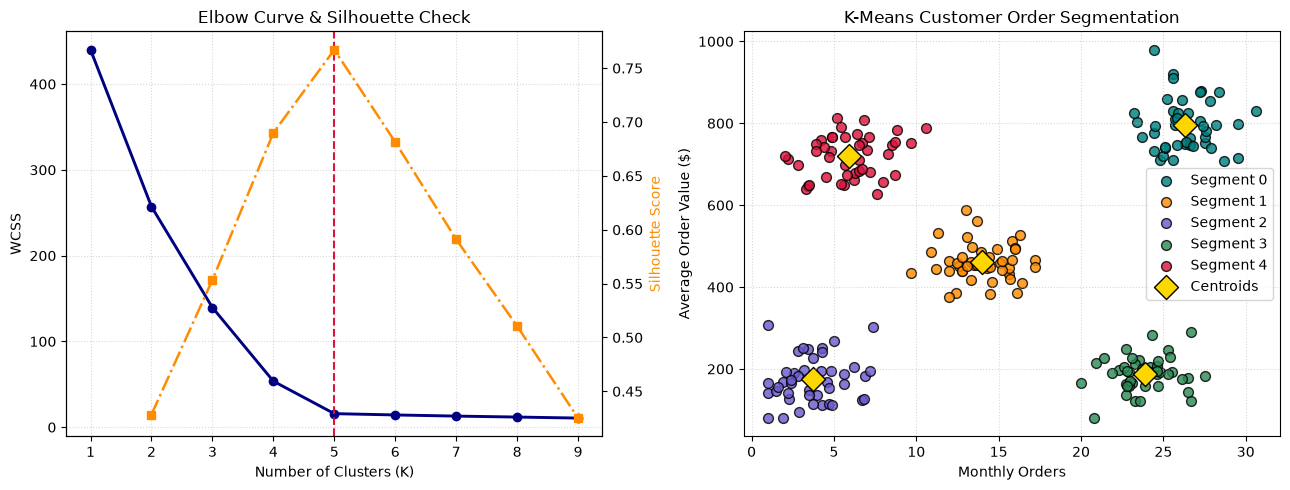

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot([1] + k_candidates, wcss_vals, marker="o", color="navy", linewidth=2.1, label="WCSS (Inertia)")
ax[0].axvline(best_k, color="crimson", linestyle="--", label=f"Best K = {best_k}")
ax[0].set_title("Elbow Curve & Silhouette Check")
ax[0].set_xlabel("Number of Clusters (K)")
ax[0].set_ylabel("WCSS")
ax[0].grid(True, linestyle=":", alpha=0.5)
ax_sil = ax[0].twinx()
ax_sil.plot(k_candidates, sil_vals, marker="s", color="darkorange", linestyle="-.", linewidth=1.8, label="Silhouette")
ax_sil.set_ylabel("Silhouette Score", color="darkorange")

seg_palette = ["teal", "darkorange", "slateblue", "seagreen", "crimson", "goldenrod"]
for cid in range(best_k):
    sub = rfm_df[rfm_df["Cluster"] == cid]
    ax[1].scatter(
        sub["Monthly_Orders"],
        sub["Avg_Order_Value"],
        color=seg_palette[cid % len(seg_palette)],
        label=f"Segment {cid}",
        alpha=0.82,
        edgecolor="black",
        s=50,
    )
ax[1].scatter(
    centers_orig[:, 0],
    centers_orig[:, 1],
    color="gold",
    marker="D",
    s=150,
    edgecolor="black",
    label="Centroids",
)
ax[1].set_title("K-Means Customer Order Segmentation")
ax[1].set_xlabel("Monthly Orders")
ax[1].set_ylabel("Average Order Value ($)")
ax[1].legend()
ax[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> Both WCSS elbow inflection and maximum Silhouette Score identify 5 cohesive customer segments with well-separated centroids.